# Example 04. Develop a voxel-based model of $P_{gap}$ from UAV-LS

This example builds a voxel-based model of directional gap probability, $P_{gap}$($\theta$), from one or more drone lidar (UAV-LS) LAZ flightlines. Beam direction vectors are derived from multi-return pulses and interpolated for single-return pulses. Ground returns are identified using the LAS classification field (class 2).

## Load all the required modules

In [1]:
import os
import json
import glob
import numpy as np
import rasterio as rio

from scipy import constants, ndimage

from pylidar_tls_canopy import voxelization, riegl_io, visualize

In [2]:
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

## Process a single flightlines on a defined voxel grid

In [3]:
laz_dir = '/gpfs/data1/vclgp/armstonj/cms_savannabio/uavls_ilcp2024/flight1_12406_day1_tls_mode/laz/'
laz_fns = ['240619_004559.laz', '240619_004821.laz', '240619_005044.laz', '240619_005307.laz', 
           '240619_005539.laz', '240619_005656.laz', '240619_005813.laz', '240619_005929.laz', 
           '240619_010047.laz', '240619_010204.laz' ,'240619_010321.laz', '240619_010437.laz', 
           '240619_010555.laz']

In [4]:
laz_fn = os.path.join(laz_dir, laz_fns[2])
vgrid = voxelization.DLSVoxelGrid()

In [5]:
#voxel_bounds = voxelization.voxel_bounds_from_file(laz_fn)

# ILCP 124_19
voxel_bounds = [547330.5, 7155549.5, 507.5, 547432.0, 7155641.0, 568.0]
voxelsize = 0.5

In [6]:
vgrid.add_laz_flightline(laz_fn, voxel_bounds=voxel_bounds)

  Spatial post-processing 19,296 pulses (19,296 flagged during segment pass)
  129,517,968 pulses  |  210,232,820 returns  |  58,079,412 multi-return  |  71,438,556 single-return


In [7]:
vgrid.voxelize_scan(voxel_bounds, voxelsize, save_counts=True)

In [8]:
outdir = '/gpfs/data1/vclgp/armstonj/cms_savannabio/uavls_ilcp2024/flight1_12406_day1_tls_mode/voxel'
name = os.path.splitext(os.path.basename(laz_fn))[0]
prefix = os.path.join(outdir, name)
vgrid.write_grids(prefix)

## Visualize the voxel grid

In [9]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

def plot_voxel_slice(vgrid, axis='x', idx=None, z_range=None, figsize=(8, 12), nodata=-9999):
    """
    ...
    z_range : (z_min, z_max) or None
        Vertical range in metres. Defaults to full extent.
    """
    bounds    = list(vgrid.bounds)
    voxelsize = vgrid.voxelsize

    def read_grid(key):
        with rio.open(vgrid.filenames[key]) as src:
            data = src.read()
        data = data.astype(float)
        data[data == nodata] = np.nan
        return data

    hits = read_grid('hits')
    miss = read_grid('miss')
    occl = read_grid('occl')

    nz, ny, nx = hits.shape

    # Subset z layers
    if z_range is not None:
        z0_idx = max(0,  int((z_range[0] - bounds[2]) / voxelsize))
        z1_idx = min(nz, int((z_range[1] - bounds[2]) / voxelsize))
        hits = hits[z0_idx:z1_idx]
        miss = miss[z0_idx:z1_idx]
        occl = occl[z0_idx:z1_idx]
        z_min = bounds[2] + z0_idx * voxelsize
        z_max = bounds[2] + z1_idx * voxelsize
    else:
        z_min, z_max = bounds[2], bounds[5]

    if axis == 'x':
        if idx is None:
            idx = ny // 2
        slc  = np.s_[:, idx, :]
        horiz_min, horiz_max = bounds[0], bounds[3]
        xlabel = 'X (m)'
        coord  = bounds[1] + (idx + 0.5) * voxelsize
        title_coord = f'Y = {coord:.1f} m  (y-index {idx})'
    elif axis == 'y':
        if idx is None:
            idx = nx // 2
        slc  = np.s_[:, :, idx]
        horiz_min, horiz_max = bounds[1], bounds[4]
        xlabel = 'Y (m)'
        coord  = bounds[0] + (idx + 0.5) * voxelsize
        title_coord = f'X = {coord:.1f} m  (x-index {idx})'
    else:
        raise ValueError("axis must be 'x' or 'y'")

    hits_s = hits[slc]
    miss_s = miss[slc]
    occl_s = occl[slc]

    total = hits_s + miss_s + occl_s
    with np.errstate(invalid='ignore', divide='ignore'):
        hits_n = np.where(total > 0, hits_s / total, np.nan)
        miss_n = np.where(total > 0, miss_s / total, np.nan)
        occl_n = np.where(total > 0, occl_s / total, np.nan)

    extent = [horiz_min, horiz_max, z_min, z_max]

    panels = [
        (hits_n, 'Hits / beams',     'YlOrRd'),
        (miss_n, 'Miss / beams',     'YlGnBu'),
        (occl_n, 'Occluded / beams', 'Purples'),
    ]

    fig, axes = plt.subplots(nrows=3, ncols=1, figsize=figsize,
                              sharex=True, sharey=True)
    fig.suptitle(f'Vertical slice — {title_coord}', fontsize=13)

    for ax, (data, label, cmap) in zip(axes, panels):
        im = ax.imshow(data, origin='lower', aspect='auto',
                       extent=extent, cmap=cmap, vmin=0, vmax=1,
                       interpolation='nearest')
        ax.set_ylabel('Z (m)')
        ax.set_title(label)
        divider = make_axes_locatable(ax)
        cax = divider.append_axes('right', size='2%', pad=0.05)
        fig.colorbar(im, cax=cax)

    axes[-1].set_xlabel(xlabel)
    fig.tight_layout()
    plt.show()

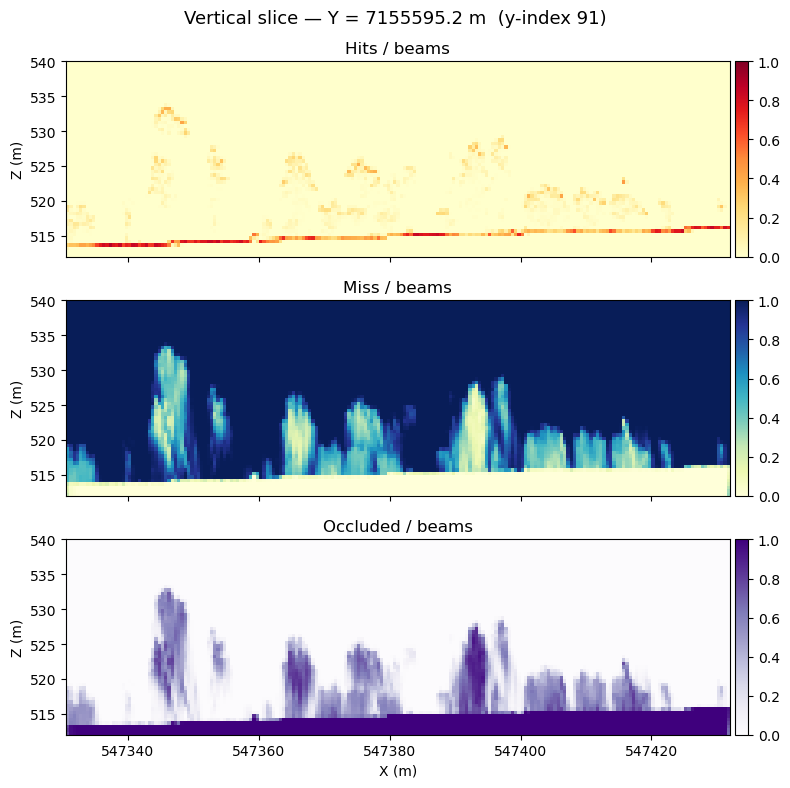

In [17]:
plot_voxel_slice(vgrid, axis='x', z_range=(512, 540), figsize=(8, 8))

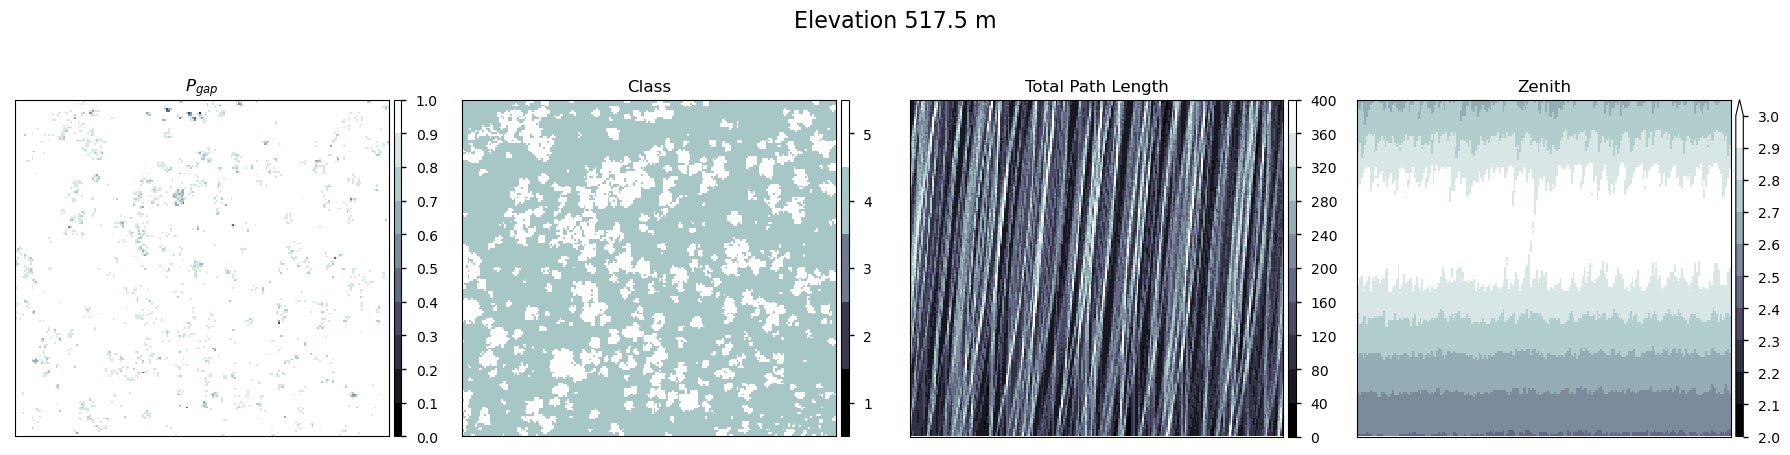

In [11]:
names = ['pgap','vcls','vwts','zeni']
z = 20
elev = voxel_bounds[2] + z * voxelsize

src = [rio.open(vgrid.filenames[k]) for k in sorted(vgrid.filenames) if k in names]
data_s = [s.read(z+1) for s in src]
clim = [[0,1],[0.5,5.5],[0,400],[2,3]]
nbins = [10,5,10,10]
title = [r'$P_{gap}$','Class','Total Path Length','Zenith']
extend = ['neither','neither','neither','max']
cmap = ['bone','bone','bone','bone']

visualize.plot_voxel_grid(data_s, title=title, clim=clim, figsize=(18,5), nbins=nbins,
                cmap=cmap, extend=extend, nodata=-9999, extent=None,
                xlabel=None, ylabel=None, facecolor='lightyellow', 
                suptitle=f'Elevation {elev:.1f} m')